# 🏠 Task 1 — Build & Evaluate a Linear Regression Model (House Price Predictor)
**Dataset:** California Housing (scikit-learn) &nbsp;|&nbsp; **Model:** `LinearRegression` &nbsp;|&nbsp; **Metrics:** MAE, RMSE, R²

This notebook follows the complete ML lifecycle, one numbered section at a time:

| # | Section | What happens |
|---|---------|--------------|
| 0 | Setup | imports, folders, random seed |
| 1 | Load data | fetch the dataset into a pandas DataFrame |
| 2 | Data overview | shape, types, missing values, duplicates, statistics |
| 3 | EDA | distributions, correlations, relationships, geography |
| 4 | Preprocessing | train/test split, scaling (inside a Pipeline) |
| 5 | Train baseline | fit Linear Regression |
| 6 | Evaluate | MAE, RMSE, R², cross-validation |
| 7 | Diagnostics | actual vs predicted, residuals, coefficients |
| 8 | Improve | feature engineering, Ridge, non-linear reference |
| 9 | Save model | pickle + reload test + sample prediction |
| 10 | Report | export results and build the PDF report |
| 11 | Conclusion | summary and next ideas |

> **How to run:** `Kernel → Restart & Run All`. Everything is reproducible (fixed seed). The first run needs internet once to download the dataset; it is then cached and a CSV copy is saved in `data/`.

## 0. Setup

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor

from housing_utils import FEATURES, TARGET, PRICE_UNIT, add_features, regression_metrics

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42                                   # reproducibility
ROOT = Path.cwd()
FIG_DIR, MODEL_DIR, DATA_DIR = ROOT / "figures", ROOT / "models", ROOT / "data"
for d in (FIG_DIR, MODEL_DIR, DATA_DIR):
    d.mkdir(exist_ok=True)

results = {}                                # everything the PDF report needs is collected here

def savefig(name):
    """Save the current figure to figures/<name>.png and display it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.1


## 1. Load the data
The dataset has **20,640 rows** (one per census block group in California, 1990) and 8 numeric features:

| Feature | Meaning |
|---|---|
| `MedInc` | median income in the block (×$10,000) |
| `HouseAge` | median house age (years) |
| `AveRooms` / `AveBedrms` | average rooms / bedrooms per household |
| `Population` | block population |
| `AveOccup` | average occupants per household |
| `Latitude` / `Longitude` | block location |

**Target:** `MedHouseVal` — median house value in units of **$100,000** (so `2.5` = $250,000).

In [2]:
CSV_COPY = DATA_DIR / "california_housing.csv"

def load_data():
    """Download via scikit-learn (cached); fall back to the local CSV copy when offline."""
    try:
        df = fetch_california_housing(as_frame=True).frame.copy()
        df.to_csv(CSV_COPY, index=False)            # keep an offline copy
        return df
    except Exception as err:
        if CSV_COPY.exists():
            print("Download failed, using local copy:", CSV_COPY)
            return pd.read_csv(CSV_COPY)
        raise RuntimeError("Could not download the dataset. Connect to the internet once "
                           "(it is cached afterwards) or place california_housing.csv in data/.") from err

df = load_data()
print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Data overview
First sanity checks: data types, missing values, duplicates and summary statistics.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
n_missing = int(df.isna().sum().sum())
n_dupes = int(df.duplicated().sum())
print(f"Missing values : {n_missing}")
print(f"Duplicate rows : {n_dupes}")
df.describe().T.round(2)

Missing values : 0
Duplicate rows : 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


**What to notice**
* No missing values → no imputation needed.
* `AveRooms`, `AveBedrms`, `AveOccup` and `Population` have a tiny median but a huge maximum → **extreme outliers / heavy skew**.
* `MedHouseVal` stops at **5.0** (= $500,000): the survey *capped* the price, so many expensive districts are recorded as exactly 5.0.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Target distribution

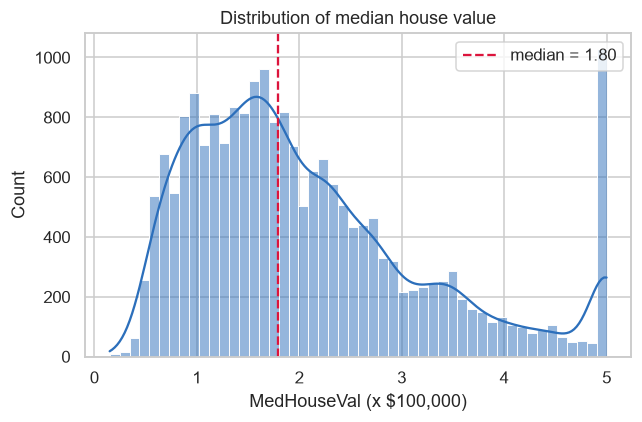

4.8% of districts are capped at 5.0 ($500k)


In [5]:
capped_pct = float((df[TARGET] >= 5.0).mean() * 100)

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(df[TARGET], bins=50, kde=True, color="#2c6fbb", ax=ax)
ax.axvline(df[TARGET].median(), color="crimson", ls="--", label=f"median = {df[TARGET].median():.2f}")
ax.set(title="Distribution of median house value", xlabel="MedHouseVal (x $100,000)")
ax.legend()
savefig("target_distribution")
print(f"{capped_pct:.1f}% of districts are capped at 5.0 ($500k)")

The target is right-skewed, and the spike at 5.0 is the price cap.

### 3.2 Feature distributions

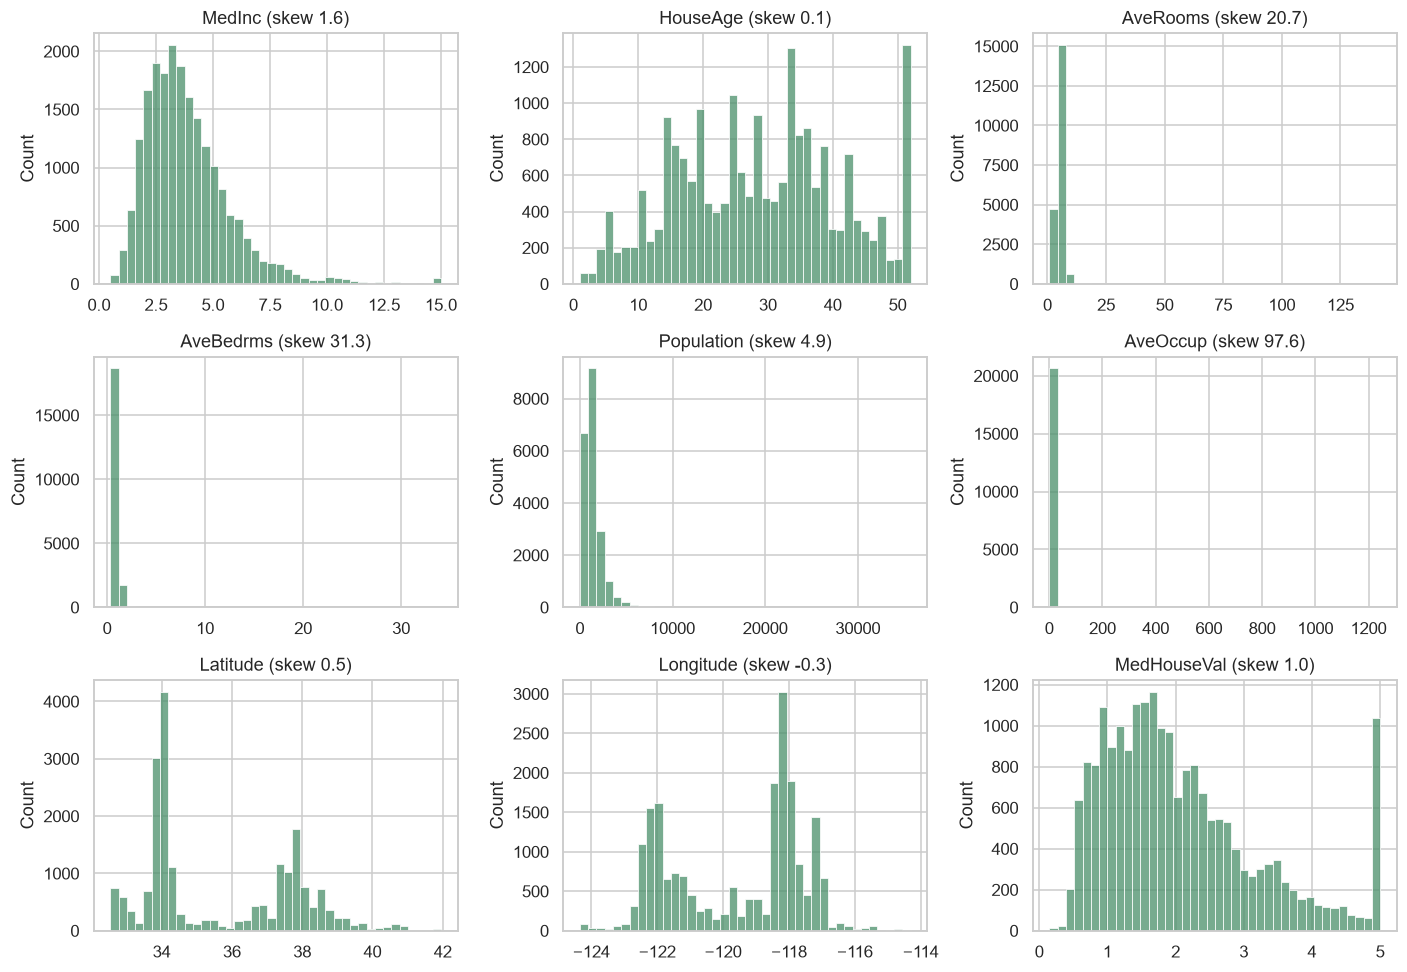

Heavily skewed features (|skew| > 1): ['MedInc', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup']


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), FEATURES + [TARGET]):
    sns.histplot(df[col], bins=40, ax=ax, color="#4a8f6a")
    ax.set_title(f"{col} (skew {df[col].skew():.1f})")
    ax.set_xlabel("")
savefig("feature_distributions")

skewed = [c for c in FEATURES if abs(df[c].skew()) > 1]
print("Heavily skewed features (|skew| > 1):", skewed)

### 3.3 Outliers (IQR rule)

In [7]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())

pd.DataFrame({"outliers": {c: iqr_outliers(df[c]) for c in FEATURES}}).assign(
    pct=lambda t: (t.outliers / len(df) * 100).round(1)).sort_values("outliers", ascending=False)

,outliers,pct
AveBedrms,1424,6.9
Population,1196,5.8
AveOccup,711,3.4
MedInc,681,3.3
AveRooms,511,2.5
HouseAge,0,0.0
Latitude,0,0.0
Longitude,0,0.0


### 3.4 Correlations

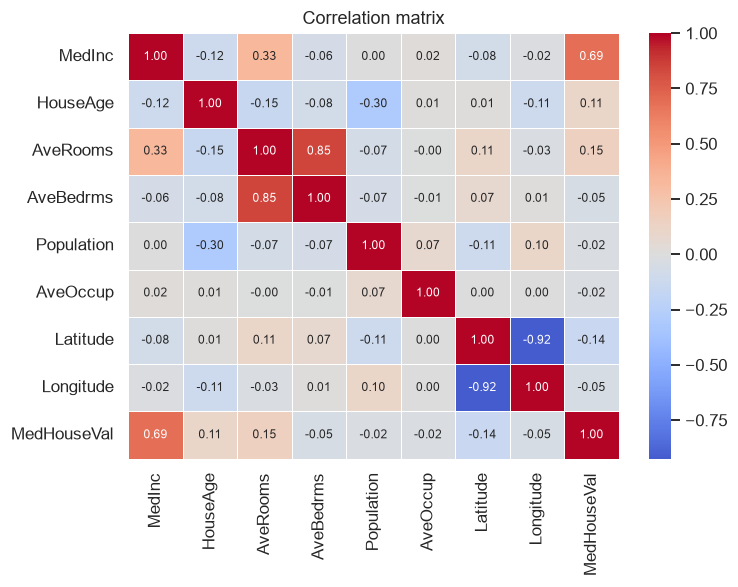

MedInc        0.688
AveRooms      0.152
Latitude     -0.144
HouseAge      0.106
AveBedrms    -0.047
Longitude    -0.046
Population   -0.025
AveOccup     -0.024
Name: MedHouseVal, dtype: float64


In [8]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation matrix")
savefig("correlation_heatmap")

target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(target_corr.round(3))

`MedInc` (median income) has by far the strongest linear relationship with price. `Latitude`/`Longitude` are only weakly *linearly* correlated, yet location clearly matters (see 3.6) — a hint that the relationship is non-linear.

### 3.5 Key relationship: income vs. price

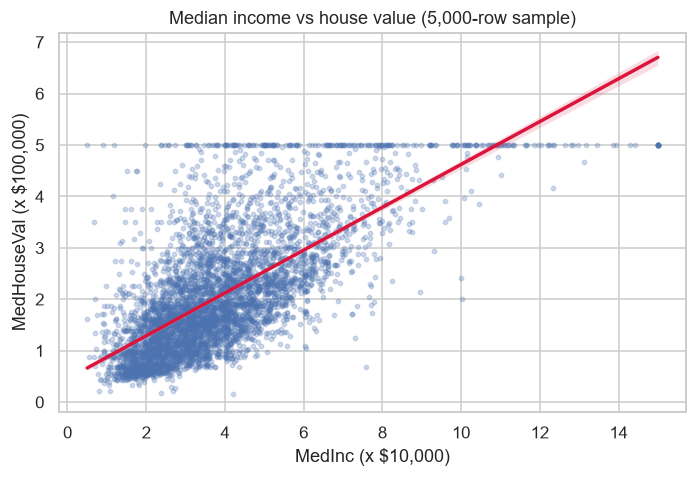

In [9]:
sample = df.sample(5000, random_state=SEED)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.regplot(data=sample, x="MedInc", y=TARGET, scatter_kws=dict(alpha=.25, s=8),
            line_kws=dict(color="crimson"), ax=ax)
ax.set(title="Median income vs house value (5,000-row sample)", xlabel="MedInc (x $10,000)", ylabel="MedHouseVal (x $100,000)")
savefig("income_vs_price")

### 3.6 Geography

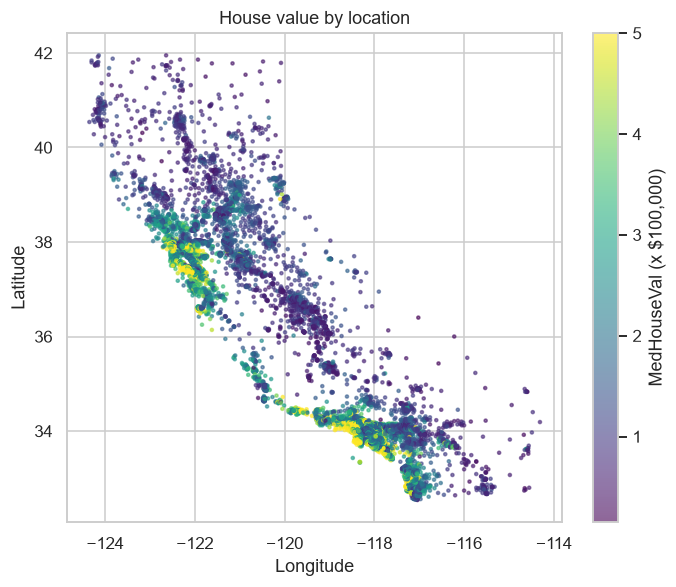

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(df["Longitude"], df["Latitude"], c=df[TARGET], s=4, cmap="viridis", alpha=.6)
plt.colorbar(sc, label="MedHouseVal (x $100,000)")
ax.set(title="House value by location", xlabel="Longitude", ylabel="Latitude")
savefig("geographic_prices")

The outline of California appears, and the most expensive districts hug the coast near **Los Angeles** and the **San Francisco Bay Area**.

In [11]:
results["dataset"] = dict(
    rows=int(len(df)), features=FEATURES, target=TARGET, missing=n_missing, duplicates=n_dupes,
    capped_pct=capped_pct, target_mean=float(df[TARGET].mean()), target_median=float(df[TARGET].median()),
    target_min=float(df[TARGET].min()), target_max=float(df[TARGET].max()))
results["eda"] = dict(top_corr=[[f, float(v)] for f, v in target_corr.items()], skewed=skewed)

## 4. Preprocessing
1. **Split first** into train (80%) and test (20%). The test set is locked away until the final evaluation.
2. **Scale** features with `StandardScaler` (mean 0, std 1). Plain least squares does not *need* scaling, but it makes coefficients comparable and helps later models.
3. Put the scaler and model in one **`Pipeline`**, so the scaler is fitted on training data only → **no data leakage**.

In [12]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
results["split"] = dict(train=len(X_train), test=len(X_test), test_size=0.2, random_state=SEED)

Train: (16512, 8) | Test: (4128, 8)


## 5. Train the baseline model

In [13]:
baseline = Pipeline([("scaler", StandardScaler()),
                     ("model", LinearRegression())])
baseline.fit(X_train, y_train)

lin = baseline.named_steps["model"]
print("Intercept:", round(lin.intercept_, 4))

Intercept: 2.0719


## 6. Evaluate
* **MAE** – average absolute error (same unit as the target).
* **RMSE** – square root of the mean squared error; punishes big mistakes more.
* **R²** – share of the variance in price explained by the model (1 = perfect, 0 = no better than predicting the mean).

We compare **train vs. test** to detect over-/under-fitting and add **5-fold cross-validation** for a more stable estimate.

In [14]:
train_m = regression_metrics(y_train, baseline.predict(X_train))
test_m = regression_metrics(y_test, baseline.predict(X_test))

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2 = cross_val_score(baseline, X_train, y_train, cv=kf, scoring="r2")

summary = pd.DataFrame({"Train": train_m, "Test": test_m}).T
summary.columns = ["MAE", "RMSE", "R2"]
display(summary.round(4))
print(f"5-fold CV R2 : {cv_r2.mean():.4f} +/- {cv_r2.std():.4f}")
print(f"Test MAE in dollars: about ${test_m['mae'] * PRICE_UNIT:,.0f}")

results["baseline"] = dict(train=train_m, test=test_m, cv_r2_mean=float(cv_r2.mean()), cv_r2_std=float(cv_r2.std()))

,MAE,RMSE,R2
Train,0.5286,0.7197,0.6126
Test,0.5332,0.7456,0.5758


5-fold CV R2 : 0.6115 +/- 0.0124
Test MAE in dollars: about $53,320


Train and test scores are almost identical → the model is **not over-fitting**. The modest R² means it is **under-fitting**: a straight line cannot capture everything that drives prices.

## 7. Diagnostics

### 7.1 Predictions and residuals

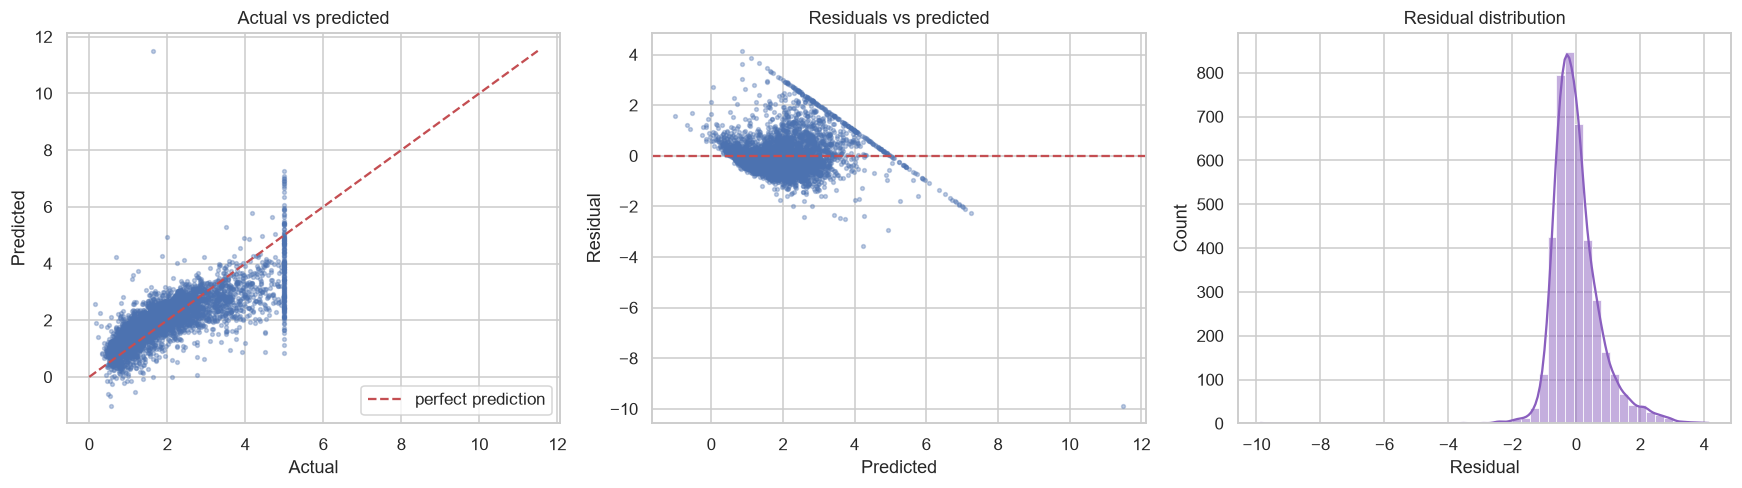

In [15]:
pred = baseline.predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].scatter(y_test, pred, s=6, alpha=.35)
lim = [0, max(y_test.max(), pred.max())]
axes[0].plot(lim, lim, "r--", label="perfect prediction")
axes[0].set(title="Actual vs predicted", xlabel="Actual", ylabel="Predicted"); axes[0].legend()

axes[1].scatter(pred, resid, s=6, alpha=.35)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(title="Residuals vs predicted", xlabel="Predicted", ylabel="Residual")

sns.histplot(resid, bins=50, kde=True, ax=axes[2], color="#8a5fbf")
axes[2].set(title="Residual distribution", xlabel="Residual")
savefig("diagnostics")

* The cloud of points bends away from the red line, especially for expensive houses (the 5.0 cap creates the diagonal streak).
* Residuals fan out as predictions grow → errors are not constant (heteroscedasticity), another hint that more flexibility would help.

### 7.2 Which features matter? (standardised coefficients)

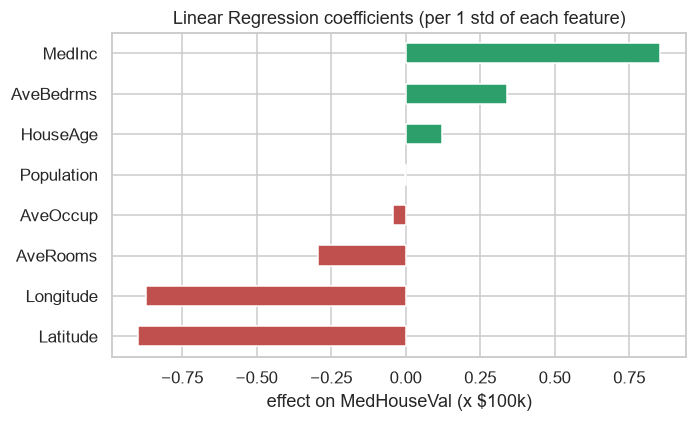

Latitude     -0.897
Longitude    -0.870
AveRooms     -0.294
AveOccup     -0.041
Population   -0.002
HouseAge      0.123
AveBedrms     0.339
MedInc        0.854
dtype: float64

In [16]:
coefs = pd.Series(lin.coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4))
coefs.plot.barh(color=np.where(coefs > 0, "#2c9f6b", "#c0504d"), ax=ax)
ax.set(title="Linear Regression coefficients (per 1 std of each feature)", xlabel="effect on MedHouseVal (x $100k)")
savefig("coefficients")
results["coefficients"] = {k: float(v) for k, v in coefs.items()}
coefs.round(3)

`MedInc` has the largest positive effect. `Latitude` and `Longitude` have large *negative* coefficients — prices fall going north and east (away from the southern coast). Note that `AveRooms` and `AveBedrms` are strongly related, so their opposite signs should not be over-interpreted.

## 8. Improvement experiments
Ideas tested, each compared using **cross-validation on the training set** (so the test set stays untouched for the final comparison):

| Model | Idea |
|---|---|
| Baseline LinearRegression | reference |
| + engineered features | ratios, log transforms, distance to LA / SF / San Diego / San Jose (`housing_utils.add_features`) |
| RidgeCV + engineered features | L2 regularisation, alpha chosen automatically |
| HistGradientBoosting | non-linear *reference* — shows the ceiling for this data |

In [17]:
def make_pipe(model, engineer=False):
    steps = [("features", FunctionTransformer(add_features))] if engineer else []
    return Pipeline(steps + [("scaler", StandardScaler()), ("model", model)])

candidates = {
    "Baseline LinearRegression": (make_pipe(LinearRegression()), "linear"),
    "LinearRegression + features": (make_pipe(LinearRegression(), engineer=True), "linear"),
    "RidgeCV + features": (make_pipe(RidgeCV(alphas=np.logspace(-3, 3, 13)), engineer=True), "linear"),
    "HistGradientBoosting (reference)": (Pipeline([("model", HistGradientBoostingRegressor(random_state=SEED))]), "non-linear"),
}

rows, fitted = [], {}
for name, (pipe, kind) in candidates.items():
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error").mean()
    pipe.fit(X_train, y_train)
    m = regression_metrics(y_test, pipe.predict(X_test))
    rows.append(dict(name=name, kind=kind, cv_rmse=float(cv_rmse), **m))
    fitted[name] = pipe

comparison = pd.DataFrame(rows).set_index("name")
display(comparison.round(4))

,kind,cv_rmse,mae,rmse,r2
name,,,,,
Baseline LinearRegression,linear,0.7205,0.5332,0.7456,0.5758
LinearRegression + features,linear,0.6620,0.4775,0.6620,0.6656
RidgeCV + features,linear,0.6692,0.4775,0.6620,0.6656
HistGradientBoosting (reference),non-linear,0.4736,0.3111,0.4654,0.8347


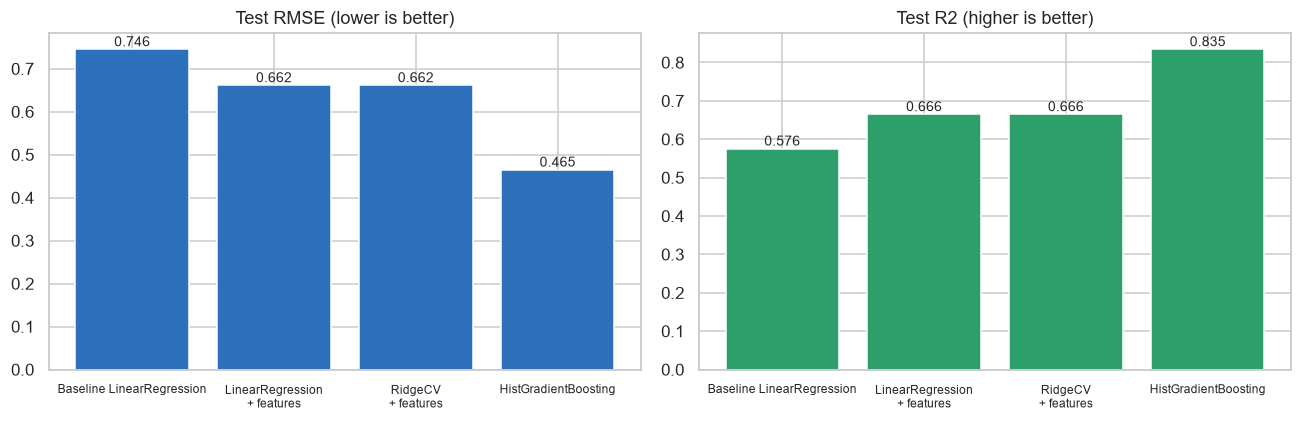

Best linear model (by CV RMSE): LinearRegression + features


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
short = [n.replace(" (reference)", "").replace(" + features", "\n+ features") for n in comparison.index]
axes[0].bar(short, comparison["rmse"], color="#2c6fbb"); axes[0].set(title="Test RMSE (lower is better)")
axes[1].bar(short, comparison["r2"], color="#2c9f6b");   axes[1].set(title="Test R2 (higher is better)")
for ax, col in zip(axes, ["rmse", "r2"]):
    for i, v in enumerate(comparison[col]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.tick_params(axis="x", labelsize=8)
savefig("model_comparison")

# choose the best LINEAR model by cross-validated RMSE (not by test score -> no peeking)
linear_only = comparison[comparison["kind"] == "linear"]
best_linear = linear_only["cv_rmse"].idxmin()
print("Best linear model (by CV RMSE):", best_linear)

results["comparison"] = [dict(name=n, **r) for n, r in comparison.iterrows()]
results["best_linear"] = best_linear

Feature engineering (especially location features) gives the linear model a clear boost, while regularisation adds little — the problem is missing signal, not over-fitting. The non-linear reference shows how much structure a linear model still misses.

## 9. Save the model
Two pickles are saved with `joblib` (the standard way to persist scikit-learn models):
* `models/linear_regression_model.pkl` – the **baseline** Task-1 model.
* `models/improved_model.pkl` – the best linear model from section 8.

Each file holds the whole pipeline (scaler included) plus metadata, so raw inputs can be passed straight in.

In [19]:
def save_bundle(pipe, path, metrics, note):
    joblib.dump({"model": pipe, "features": FEATURES, "target_unit": "USD 100,000",
                 "sklearn_version": sklearn.__version__, "metrics": metrics, "note": note}, path)

best_pipe = fitted[best_linear]
save_bundle(baseline, MODEL_DIR / "linear_regression_model.pkl", test_m, "Baseline: StandardScaler + LinearRegression")
save_bundle(best_pipe, MODEL_DIR / "improved_model.pkl", comparison.loc[best_linear, ["mae", "rmse", "r2"]].to_dict(), best_linear)

# --- reload test: the loaded model must give identical predictions
loaded = joblib.load(MODEL_DIR / "linear_regression_model.pkl")
assert np.allclose(loaded["model"].predict(X_test), baseline.predict(X_test))
print("Pickle reload test passed.\n")

# --- predict on a brand-new house
new_house = pd.DataFrame([dict(MedInc=5.0, HouseAge=20, AveRooms=6.0, AveBedrms=1.0,
                               Population=1500, AveOccup=3.0, Latitude=37.8, Longitude=-122.3)])
print(f"Baseline model : ${loaded['model'].predict(new_house)[0] * PRICE_UNIT:,.0f}")
print(f"Improved model : ${best_pipe.predict(new_house)[0] * PRICE_UNIT:,.0f}")

Pickle reload test passed.

Baseline model : $261,850
Improved model : $263,797


You can also predict outside the notebook:

```bash
python predict.py --MedInc 5.0 --Latitude 37.8 --Longitude -122.3
streamlit run app.py        # small web UI
```

## 10. Export results and build the PDF report

In [20]:
(ROOT / "results.json").write_text(json.dumps(results, indent=2))

import generate_report
pdf_path = generate_report.build_report(ROOT)
print("Report created:", pdf_path)

Report created: C:\Users\User\Downloads\Task1_Linear_Regression\Task1_Linear_Regression\Task1_Linear_Regression_Report.pdf


## 11. Conclusion

In [21]:
b, bl_best = results["baseline"]["test"], comparison.loc[best_linear]
print(f"Baseline (test)   : MAE {b['mae']:.3f} (~${b['mae']*PRICE_UNIT:,.0f}) | RMSE {b['rmse']:.3f} | R2 {b['r2']:.3f}")
print(f"Best linear model : {best_linear}")
print(f"                    MAE {bl_best['mae']:.3f} | RMSE {bl_best['rmse']:.3f} | R2 {bl_best['r2']:.3f}")

Baseline (test)   : MAE 0.533 (~$53,320) | RMSE 0.746 | R2 0.576
Best linear model : LinearRegression + features
                    MAE 0.478 | RMSE 0.662 | R2 0.666


### Key takeaways
* A plain Linear Regression pipeline is a quick, interpretable baseline; **median income** drives price the most.
* Train ≈ test performance → the model **under-fits**; more capacity/features help more than regularisation.
* Location features (distance to big cities) are the most effective cheap improvement for a linear model.

### Ideas for further improvement
1. Treat the price cap (5.0) — remove capped rows or model them separately; try a log-transformed target.
2. Polynomial / interaction terms and splines on latitude & longitude.
3. Tree ensembles (Random Forest, Gradient Boosting) with hyper-parameter search.
4. Spatial features such as the average price of the k nearest districts.
5. Error analysis by region and price band.

### Limitations
1990 census data, block-group averages (not single houses), capped target — **not for real valuation**.